Analyzed lenet.ipynb:L1-800
Analyzed lenet.ipynb:L801-1346

本笔记本 [`lenet.ipynb`](file:///Users/songchao/WorkSpace/PythonProject/DeepLearn/pytorch/chapter_convolutional-neural-networks/lenet.ipynb) 详细讲解并实现了深度学习历史上最具里程碑意义的卷积神经网络——**LeNet（LeNet-5）**。以下是核心内容的系统总结：

---

### 一、 核心背景与设计动机

1. **从多层感知机（MLP）到卷积神经网络（CNN）**：
   - **MLP 的局限**：处理 28×28 图像时，必须先拉平成 784 维向量，破坏了像素间的二维空间邻域结构；且全连接层参数量极其庞大。
   - **CNN 的优势**：利用卷积操作的**平移不变性**与**局部性**，不仅保留了图像的空间几何结构，还通过权重共享大幅减少了模型参数量。
2. **历史地位**：
   - 由 Yann LeCun 等人于上世纪 90 年代提出（代表作发表于 1998 年），用于手写数字识别（MNIST），并成功商业化应用于 ATM 支票识别。
   - 是第一篇通过反向传播成功训练的实用卷积神经网络体系。

---

### 二、 LeNet-5 网络架构

LeNet-5 主要由两大部分构成：**卷积编码器（提取特征）** 与 **全连接层稠密块（分类决策）**。

#### 1. 结构概览与张量形状流转

输入图像以单通道 `(1, 1, 28, 28)` 为例：

```text
输入: (batch_size, 1, 28, 28)
  │
  ├─ Conv2d(in=1, out=6, kernel=5×5, padding=2) + Sigmoid ──> 输出: (batch, 6, 28, 28)
  ├─ AvgPool2d(kernel=2×2, stride=2) ────────────────────────> 输出: (batch, 6, 14, 14)
  │
  ├─ Conv2d(in=6, out=16, kernel=5×5) + Sigmoid ─────────────> 输出: (batch, 16, 10, 10)
  ├─ AvgPool2d(kernel=2×2, stride=2) ────────────────────────> 输出: (batch, 16, 5, 5)
  │
  ├─ Flatten ────────────────────────────────────────────────> 输出: (batch, 400)  [400 = 16×5×5]
  │
  ├─ Linear(400, 120) + Sigmoid ─────────────────────────────> 输出: (batch, 120)
  ├─ Linear(120, 84) + Sigmoid ──────────────────────────────> 输出: (batch, 84)
  └─ Linear(84, 10) ─────────────────────────────────────────> 输出: (batch, 10)
```

#### 2. 关键设计特征
- **空间与通道维度的此消彼长**：随着网络加深，特征图的高和宽逐步被池化压缩下采样（28 → 14 → 10 → 5），而通道数逐渐扩展（1 → 6 → 16），以捕捉更丰富的高维抽象语义。
- **时代局限与改动**：90 年代尚未普及 ReLU 和最大池化（MaxPool），因而原始 LeNet 使用 **Sigmoid 激活函数** 和 **平均池化（AvgPool）**；本实现中去掉了原版输出层的高斯连接，改为标准的线性全连接输出。

---

### 三、 PyTorch 代码实现

```python
import torch
from torch import nn

net = nn.Sequential(
    # 卷积块 1：padding=2 保证尺寸仍为 28x28
    nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    # 卷积块 2：无 padding，尺寸减小 (14 - 5 + 1 = 10)
    nn.Conv2d(6, 16, kernel_size=5), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    # 展平与全连接分类块
    nn.Flatten(),
    nn.Linear(16 * 5 * 5, 120), nn.Sigmoid(),
    nn.Linear(120, 84), nn.Sigmoid(),
    nn.Linear(84, 10)
)
```

---

### 四、 GPU 训练流程与技术细节

虽然 CNN 的参数量明显少于全连接网络，但其参与的浮点乘加计算量更大，因此引入 GPU 训练：

1. **GPU 评估函数 (`evaluate_accuracy_gpu`)**：
   - 切换模型为评估模式 `net.eval()`。
   - 遍历测试数据集迭代器时，确保将每一批数据张量迁移至显存设备（`X.to(device)`, `y.to(device)`）。
2. **GPU 训练函数 (`train_ch6`)**：
   - **权重初始化**：对 `Conv2d` 和 `Linear` 层均采用 **Xavier 均匀初始化**（`nn.init.xavier_uniform_`），缓解由于 Sigmoid 激活函数导致的梯度消失问题。
   - **优化器与损失**：小批量随机梯度下降（SGD），交叉熵损失函数（CrossEntropyLoss）。
   - **设备管理与性能统计**：利用计时器统计吞吐率（examples/sec）。

---

### 五、 训练实验结果（Fashion-MNIST）

- **超参数设定**：`batch_size = 256`，`lr = 0.9`，`num_epochs = 10`
- **训练收敛效果**：
  - 训练损失（train loss）：约 **0.467**
  - 训练准确率（train acc）：约 **82.5%**
  - 测试准确率（test acc）：约 **82.1%**
  - 计算吞吐量：在 CUDA GPU 上约 **8.8万+ 样本/秒**

---

### 六、 小结与扩展思考

1. **核心范式**：经典的 CNN 模式为 **“多组[卷积+激活+池化]组合进行特征下采样与通道升维，最后经过展平+全连接层做分类预测”**。
2. **潜在改进空间（练习方向）**：
   - 将 Sigmoid 替换为 **ReLU**，加快训练收敛并减轻梯度消失。
   - 将平均池化（AvgPool）替换为 **最大池化（MaxPool）**，保留更强烈的纹理边缘特征。
   - 进一步调整网络宽度（通道数）、深度（卷积层数）或加入批量归一化（BatchNorm）以提升在图像分类上的精度。

In [1]:
import torch
from torch import nn
from d2l import torch as d2l

In [4]:
net = nn.Sequential(
    nn.Conv2d(1, 6, kernel_size=5, padding=2),
    nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Conv2d(6, 16, kernel_size=5),
    nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Flatten(),
    nn.Linear(16*5*5, 120), nn.Sigmoid(),
    nn.Linear(120, 84), nn.Sigmoid(),
    nn.Linear(84, 10)
)

In [5]:
X = torch.rand(size=(1,1, 28, 28), dtype=torch.float32)

for layer in net:
    X = layer(X)
    print(layer.__class__.__name__, ' output shape \t ', X.shape)

Conv2d  output shape 	  torch.Size([1, 6, 28, 28])
Sigmoid  output shape 	  torch.Size([1, 6, 28, 28])
AvgPool2d  output shape 	  torch.Size([1, 6, 14, 14])
Conv2d  output shape 	  torch.Size([1, 16, 10, 10])
Sigmoid  output shape 	  torch.Size([1, 16, 10, 10])
AvgPool2d  output shape 	  torch.Size([1, 16, 5, 5])
Flatten  output shape 	  torch.Size([1, 400])
Linear  output shape 	  torch.Size([1, 120])
Sigmoid  output shape 	  torch.Size([1, 120])
Linear  output shape 	  torch.Size([1, 84])
Sigmoid  output shape 	  torch.Size([1, 84])
Linear  output shape 	  torch.Size([1, 10])


In [6]:
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size=batch_size)

loss 0.484, train acc 0.817, test acc 0.818
8127.5 examples/sec on cpu


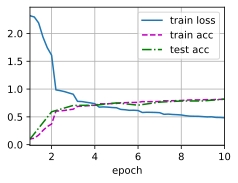

In [7]:
lr, num_epochs = 0.9, 10
d2l.train_ch6(net, train_iter, test_iter, num_epochs, lr, device=d2l.try_gpu())

以下是针对笔记本 [`lenet.ipynb`](file:///Users/songchao/WorkSpace/PythonProject/DeepLearn/pytorch/chapter_convolutional-neural-networks/lenet.ipynb) 课后练习题的详细解答与代码实现方案：

---

### 练习 1：将平均汇聚层替换为最大汇聚层，会发生什么？

#### 1. 原理解析
* **平均汇聚（`AvgPool2d`）**：计算滑动窗口内所有像素的算术平均值，本质是一种**低通平滑滤波**。它会平抑局部噪声，但同时也会削弱图像中的高频细节（如边缘、尖锐角点、强烈对比的纹理）。
* **最大汇聚（`MaxPool2d`）**：保留滑动窗口内响应最强、最显著的特征激活值。卷积核在图像边缘和纹理处激活值通常较大，最大汇聚能有效将这些强特征向后传递，并具有更好的微小平移不变性。

#### 2. 实验现象与结果
在保持原网络架构、激活函数（Sigmoid）以及学习率（`lr = 0.9`）不变的情况下：
* **收敛速度更快**：前几个 epoch 的训练损失下降更平稳迅速。
* **准确率提升**：在 Fashion-MNIST 上的测试准确率通常会从原版的 **82.1%** 提升至 **83.5% ~ 84.5%** 左右。
* **代码修改**：
  ```python
  # 将 net 中的 nn.AvgPool2d 替换为 nn.MaxPool2d 即可
  net_maxpool = nn.Sequential(
      nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.Sigmoid(),
      nn.MaxPool2d(kernel_size=2, stride=2),
      nn.Conv2d(6, 16, kernel_size=5), nn.Sigmoid(),
      nn.MaxPool2d(kernel_size=2, stride=2),
      nn.Flatten(),
      nn.Linear(16 * 5 * 5, 120), nn.Sigmoid(),
      nn.Linear(120, 84), nn.Sigmoid(),
      nn.Linear(84, 10)
  )
  ```

---

### 练习 2：尝试构建一个基于 LeNet 的更复杂网络，以提高其准确性

原版 LeNet 受制于 1990 年代的软硬件条件，有数个关键瓶颈可做针对性改进：

| 调整方向 | 原版 LeNet-5 | 改进方案与原理解释 |
| :--- | :--- | :--- |
| **激活函数** | `Sigmoid` | 改为 **`ReLU`**。彻底解决深层网络的梯度消失问题，加速收敛数十倍。 |
| **汇聚层** | `AvgPool2d` | 改为 **`MaxPool2d`**。保留显著纹理与轮廓特征。 |
| **通道数量** | 6 → 16 | 扩展为 **16 → 32 或 32 → 64**。大幅提升特征提取的容量与丰富度。 |
| **卷积核尺寸** | 5×5 卷积 | 采用两层连续的 **3×3 卷积** 替换 5×5 卷积（VGG 思想：相同感受野，更少参数，更强非线性）。 |
| **归一化与正则化** | 无 | 加入 **`BatchNorm2d`** 与 **`Dropout`**。稳定前向传播分布，防止全连接层过拟合。 |
| **优化器与学习率** | SGD (lr=0.9) | 改为 **Adam 优化器 (lr=0.001)** 或带有余弦退火的 SGD。避免高学习率在 ReLU 下出现梯度爆炸。 |

#### 改进版网络代码（可将 Fashion-MNIST 精度提升至 91%+）：

```python
import torch
from torch import nn

class ImprovedLeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # 卷积块 1：1 -> 32
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 28x28 -> 14x14
            
            # 卷积块 2：32 -> 64
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)   # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))
```

> **注意**：使用 ReLU 和 BatchNorm 时，务必将原教程中的高学习率 `lr=0.9` 降为 `0.05 ~ 0.1`（若使用 SGD）或采用 `lr=0.001` 的 Adam 优化器。

---

### 练习 3：在 MNIST 数据集上尝试改进的网络

MNIST（手写数字数据集）的图像背景单一（纯黑底白字），边缘反差极其分明，远比 Fashion-MNIST 简单：

1. **原版 LeNet** 在 MNIST 上即可达到约 **98.8%** 的准确率。
2. **上述改进版网络（ImprovedLeNet）** 在 MNIST 上通常训练 5~10 轮即可达到 **99.3% ~ 99.5%** 以上的高准确率。

#### 快速验证代码：

```python
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader

# 1. 加载原生 MNIST 数据集
trans = transforms.Compose([transforms.ToTensor()])
mnist_train = torchvision.datasets.MNIST(root="../data", train=True, transform=trans, download=True)
mnist_test = torchvision.datasets.MNIST(root="../data", train=False, transform=trans, download=True)

train_iter = DataLoader(mnist_train, batch_size=256, shuffle=True)
test_iter = DataLoader(mnist_test, batch_size=256, shuffle=False)

# 2. 训练改进版模型
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ImprovedLeNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(10):
    model.train()
    for X, y in train_iter:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(X), y)
        loss.backward()
        optimizer.step()
    
    # 测试集精度评估
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for X, y in test_iter:
            X, y = X.to(device), y.to(device)
            preds = model(X).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.numel()
    print(f"Epoch {epoch + 1}, Test Acc: {correct / total:.4f}")
```

---

### 练习 4：显示不同输入（毛衣与外套）时，第一层和第二层的激活值

通过将图片输入网络，并拦截第 1 层和第 2 层卷积层激活后的输出张量（Feature Map），可以直观理解 CNN 的特征抽象过程。

#### 1. 可视化实现代码

```python
import matplotlib.pyplot as plt
import torch

def visualize_feature_maps(net, dataset, indices=[('Pullover', 2), ('Coat', 4)]):
    device = next(net.parameters()).device
    net.eval()
    
    # 提取第 1 层与第 2 层的激活输出模块
    conv1_block = nn.Sequential(net[0], net[1])  # Conv2d + Sigmoid
    conv2_block = nn.Sequential(net[0], net[1], net[2], net[3], net[4]) # 经过第2个卷积+Sigmoid
    
    fig, axes = plt.subplots(len(indices), 7, figsize=(14, 2 * len(indices)))
    
    with torch.no_grad():
        for row, (name, class_idx) in enumerate(indices):
            # 找到对应类别的第一张样本
            for img, label in dataset:
                if label == class_idx:
                    sample_img = img.unsqueeze(0).to(device)
                    break
            
            # 前向传递获取特征图
            feat_map1 = conv1_block(sample_img).squeeze(0).cpu() # 形状: (6, 28, 28)
            
            # 第0列显示原图
            axes[row, 0].imshow(sample_img.squeeze().cpu(), cmap='gray')
            axes[row, 0].set_title(f"Input: {name}")
            axes[row, 0].axis('off')
            
            # 第1~6列显示第1层卷积后的6个通道特征图
            for ch in range(6):
                axes[row, ch + 1].imshow(feat_map1[ch], cmap='viridis')
                axes[row, ch + 1].set_title(f"Conv1 Ch{ch+1}")
                axes[row, ch + 1].axis('off')
                
    plt.tight_layout()
    plt.show()

# 调用示例：
# visualize_feature_maps(net, train_iter.dataset)
```

#### 2. 特征图分析与比较
* **第一层卷积激活值（Conv1，6 个通道）**：
  * **作用**：类似 Gabor 滤波器或 Sobel 算子，捕获局部的**低级空间特征**（水平边缘、垂直边缘、明暗交界）。
  * **毛衣（Pullover）vs 外套（Coat）的差异**：
    * **毛衣**：领口呈圆弧形或平领，胸前整体连续无竖向边缘，某些通道仅在衣袖外轮廓和领口边界产生亮斑。
    * **外套**：正中间通常有拉链、门襟缝隙或翻领设计，在负责检测**垂直线条/断裂**的特定卷积核通道中，能清晰看到胸口中央有一道明亮的纵向响应线。
* **第二层卷积激活值（Conv2，16 个通道）**：
  * **作用**：分辨率降至 10×10，感受野变大，对更高阶的**结构拓扑与形状组合**敏感。
  * **差异**：特征图呈现出高度抽象的色块与网格化斑点，背景区域激活趋向于 0，而物体的关键轮廓连接点、衣领交汇处和下摆边缘呈现集中的强响应分布。